# ДЗ 3. Ошибки и устойчивость E3

Средний ROC-AUC модели E3 в ДЗ 2 составил **0,958076**. Модель при этом заметно лучше ранжирует ответы в деловых поездках, чем в личных. Разберём ошибки в этих группах и проверим, как меняется общая метрика при смене разбиения и сокращении обучающей выборки. [ДЗ 2](02_model_and_ablation.ipynb)

## Данные и протокол

| Что фиксируем | Как считаем |
|---|---|
| Модель | LightGBM с 21 исходным признаком и произведением оценок кресла и развлечений |
| Выбор E3 | Наибольший средний ROC-AUC в ДЗ 2. Преимущество перед E1 составило 0,000037 на тех же фолдах |
| Данные | 699 635 строк конкурсного `train.csv`. Пять стратифицированных фолдов, seed 42 |
| Метрика | Средний ROC-AUC по фолдам. Ошибки считаем при пороге 0,5 |
| Контроль утечек | Для каждой строки берём прогноз модели, обученной без этой строки. Это out-of-fold-прогноз (OOF). Предобработку настраиваем на обучающей части фолда |

Скрипт сверяет хеш данных, состав фолдов, ID, метки и метрики с ДЗ 2. Настройки взяли из ДЗ 2. Тестовую выборку и таблицу лидеров не использовали. Для оценки преимущества E3 нужны независимые данные. [Таблица экспериментов ДЗ 2](../reports/hw2/summary.csv) · [Настройки LightGBM](../configs/hw2.yaml)

In [1]:
from itertools import count
from pathlib import Path

import pandas as pd
from IPython.display import Image, display

root = Path.cwd()
if not (root / "reports/hw3").is_dir():
    root = root.parent
report = root / "reports/hw3"
table_ids = count(1)

def read(name):
    return pd.read_csv(report / f"{name}.csv")

def show(table, formats=None):
    styled = table.style.hide(axis="index").set_uuid(f"hw3_{next(table_ids)}")
    text_columns = table.select_dtypes(include=["object", "string"]).columns
    styled = styled.set_properties(subset=text_columns, **{"text-align": "left"})
    display(styled.format(formats or {}, decimal=",", thousands=" "))

def integer(value):
    return f"{int(value):,}".replace(",", " ")

def fraction(n, total):
    return f"{integer(n)} / {integer(total)}"

def share(n, total):
    percent = f"{n / total:.1%}".replace(".", ",")
    return f"{percent} ({fraction(n, total)})"

## Где ошибается модель

При пороге 0,5 модель допустила **52 282 ошибки**. FP означает ложный прогноз удовлетворённости, FN означает пропуск положительного ответа. В таблице указаны число ошибок и доля от всех ошибок. Калибровку оценок модели не проверяли.

In [2]:
counts = read("error_counts")
counts["Ошибок"] = [
    f"{integer(n)} ({p:.1%})".replace(".", ",")
    for n, p in zip(counts.n, counts.share_of_errors)
]
bands = ["Около порога", "Между диапазонами", "Край шкалы"]
by_band = counts.pivot(index="band", columns="kind", values="Ошибок").loc[bands, ["FP", "FN"]]
by_band["Оценка модели"] = ["[0,4; 0,6)", "Остальные", "≤ 0,1 или ≥ 0,9"]
show(by_band.reset_index(names="Диапазон")[["Диапазон", "Оценка модели", "FP", "FN"]])

Диапазон,Оценка модели,FP,FN
Около порога,"[0,4; 0,6)","3 971 (7,6%)","4 141 (7,9%)"
Между диапазонами,Остальные,"5 814 (11,1%)","12 980 (24,8%)"
Край шкалы,"≤ 0,1 или ≥ 0,9","12 537 (24,0%)","12 839 (24,6%)"


### Четыре примера ошибок

Выбрали по одному FP и FN около порога и на краю шкалы. В каждой группе брали строку с оценкой, ближайшей к медиане группы. При равенстве выбирали меньший ID. Исходные ID в таблице опущены.

In [3]:
examples = read("error_examples")
show(pd.DataFrame({
    "№": examples.example,
    "Тип": examples.error + " · " + examples.band.str.lower(),
    "Поездка · класс": examples.travel + " · " + examples.service_class,
    "Факт": examples.target.map({0: "Не удовлетворён", 1: "Удовлетворён"}),
    "Оценка E3": examples.score,
}), {"Оценка E3": "{:.3f}"})

№,Тип,Поездка · класс,Факт,Оценка E3
1,FP · около порога,Деловая · Business,Не удовлетворён,"0,545"
2,FP · край шкалы,Деловая · Business,Не удовлетворён,"0,951"
3,FN · около порога,Деловая · Business,Удовлетворён,"0,452"
4,FN · край шкалы,Личная · Eco,Удовлетворён,"0,040"


Для каждого примера сравнили долю строк с такой же парой оценок среди ошибок и верных прогнозов. В каждой паре групп совпадали фактический ответ, тип поездки и класс обслуживания. Ошибки брали из того же диапазона, что и пример. Оценки кресла и развлечений сгруппировали в диапазоны 0–2, 3 и 4–5.

In [4]:
evidence = []
for row in examples.itertuples():
    evidence.append({
        "№": str(row.example),
        "Оценки из примера": f"Кресло {row.seat_band}, развлечения {row.entertainment_band}",
        "Среди ошибок": share(row.same_pattern_errors, row.n_errors),
        "Среди верных прогнозов": share(row.same_pattern_correct, row.n_correct),
    })
    if pd.notna(row.boarding_band):
        evidence.append({
            "№": f"{row.example}*",
            "Оценки из примера": f"Онлайн-посадка {int(row.boarding_band)}",
            "Среди ошибок": share(row.boarding_errors, row.n_errors),
            "Среди верных прогнозов": share(row.boarding_correct, row.n_correct),
        })
show(pd.DataFrame(evidence))

№,Оценки из примера,Среди ошибок,Среди верных прогнозов
1,"Кресло 4–5, развлечения 4–5","45,3% (872 / 1 926)","17,0% (12 514 / 73 814)"
2,"Кресло 4–5, развлечения 4–5","85,8% (9 652 / 11 247)","17,0% (12 514 / 73 814)"
3,"Кресло 3, развлечения 0–2","1,7% (26 / 1 526)","0,2% (420 / 241 232)"
4,"Кресло 3, развлечения 3","15,1% (833 / 5 509)","15,8% (1 000 / 6 349)"
4*,Онлайн-посадка 3,"31,1% (1 715 / 5 509)","2,4% (151 / 6 349)"


- **Случаи 1–2.** Среди ложноположительных прогнозов чаще встречаются высокие оценки обеих услуг. На краю шкалы разница заметнее. Возможно, высокие оценки услуг смещают прогноз в сторону удовлетворённости.
- **Случай 3.** Сочетание низкой оценки развлечений и средней оценки кресла встречается редко, но среди пропусков около порога оно встречается чаще, чем среди верных прогнозов. Такое сочетание могло сместить прогноз в сторону отрицательного ответа.
- **Случай 4.** Доли совпадений по паре оценок близки. Оценка 3 за онлайн-посадку заметно чаще встречается среди пропусков на краю шкалы. Её проверили после просмотра примера, поэтому отметили строку звёздочкой.

Эти сравнения помогают выбрать группы для дальнейшего анализа. Чтобы выяснить, как отдельный признак влияет на прогноз, нужен отдельный эксперимент.

## Качество по типу поездки и классу обслуживания

Снова проверяем разрыв между типами поездок, который заметили в ДЗ 2. По классам обслуживания сравниваем группы с разными условиями поездки. В каждом срезе усредняем ROC-AUC по пяти фолдам. Отдельно считаем ROC-AUC по объединённым OOF-прогнозам, где участвуют и пары строк из разных фолдов.

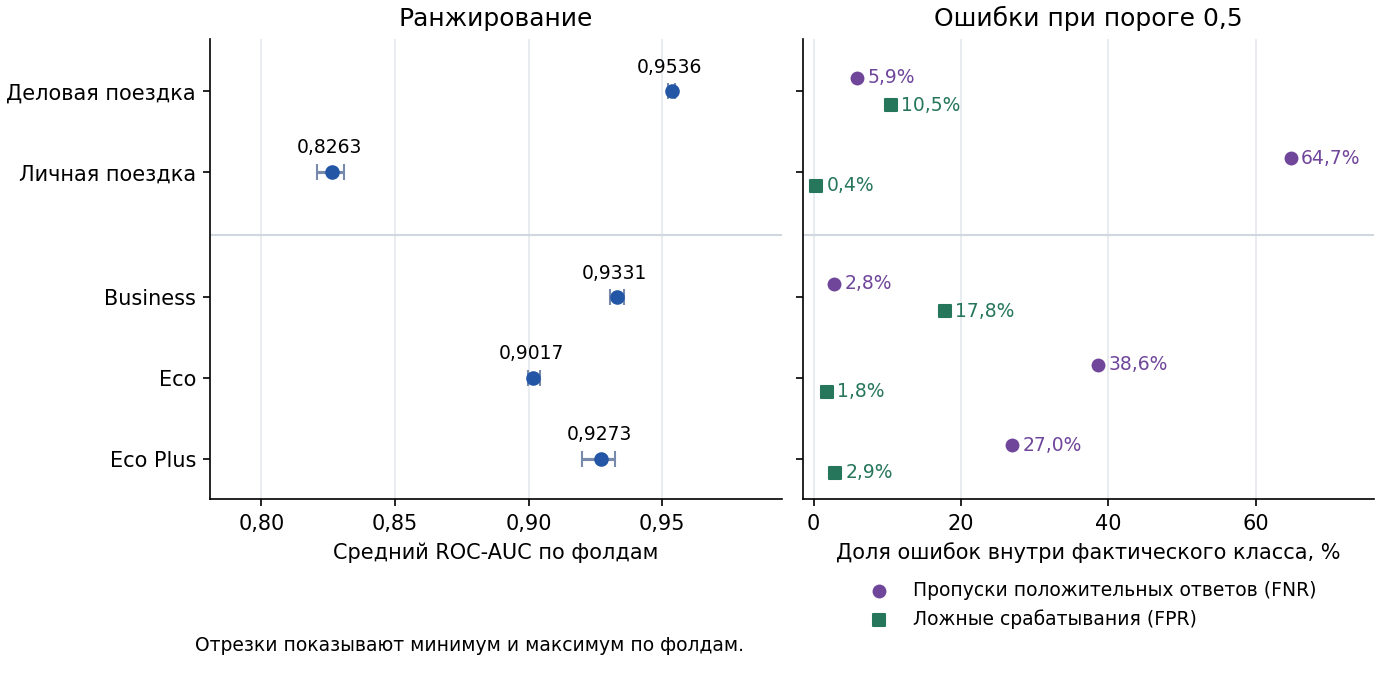

Группа,Строк,Ответы + / −,ROC-AUC,OOF ROC-AUC,FN / +,FP / −
Деловая,497 441,290 673 / 206 768,"0,95355","0,95354",17 229 / 290 673,21 661 / 206 768
Личная,202 194,19 666 / 182 528,"0,82634","0,82618",12 731 / 19 666,661 / 182 528
Business,342 212,248 210 / 94 002,"0,93306","0,93303",6 829 / 248 210,16 710 / 94 002
Eco,327 404,54 859 / 272 545,"0,90167","0,90163",21 170 / 54 859,4 944 / 272 545
Eco Plus,30 019,7 270 / 22 749,"0,92727","0,92727",1 961 / 7 270,668 / 22 749


In [5]:
display(Image(filename=str(report / "slices.png"),
              alt="ROC-AUC и доли ошибок по типу поездки и классу. В личных поездках при пороге 0,5 модель пропускает 64,7% положительных ответов."))
slices = read("slices")
show(pd.DataFrame({
    "Группа": slices.group,
    "Строк": slices.n,
    "Ответы + / −": [fraction(p, n) for p, n in zip(slices.positive, slices.negative)],
    "ROC-AUC": slices.mean_fold_auc,
    "OOF ROC-AUC": slices.pooled_oof_auc,
    "FN / +": [fraction(fn, total) for fn, total in zip(slices.fn, slices.positive)],
    "FP / −": [fraction(fp, total) for fp, total in zip(slices.fp, slices.negative)],
}), {"ROC-AUC": "{:.5f}", "OOF ROC-AUC": "{:.5f}"})

- **Тип поездки.** При пороге 0,5 модель пропускает 64,7% положительных ответов в личных поездках и 5,9% в деловых. Ложных срабатываний меньше в личных поездках. Долю пропусков считаем среди положительных ответов, долю ложных срабатываний среди отрицательных.
- **Класс обслуживания.** ROC-AUC ниже всего в Eco. В Eco Plus меньше всего строк, а разброс ROC-AUC между фолдами шире, чем в других классах. Тип поездки и класс обслуживания пересекаются, поэтому по этим срезам трудно установить, что именно объясняет разницу.

## Устойчивость

| Проверка | Меняем | Сохраняем |
|---|---|---|
| Смена разбиения | Seed разбиения 42, 13 и 73 | Полную обучающую часть и настройки модели, включая её seed 42 |
| Размер обучающей части | 100%, 50% и 20% обучающих строк исходного фолда | Те же проверочные строки и настройки модели |

Подвыборки стратифицированы. В каждом фолде подвыборка 20% входит в подвыборку 50%. Строки отбираем с seed `20261124` и возвращаем исходный порядок. Предобработку и модель обучаем заново на каждой подвыборке.

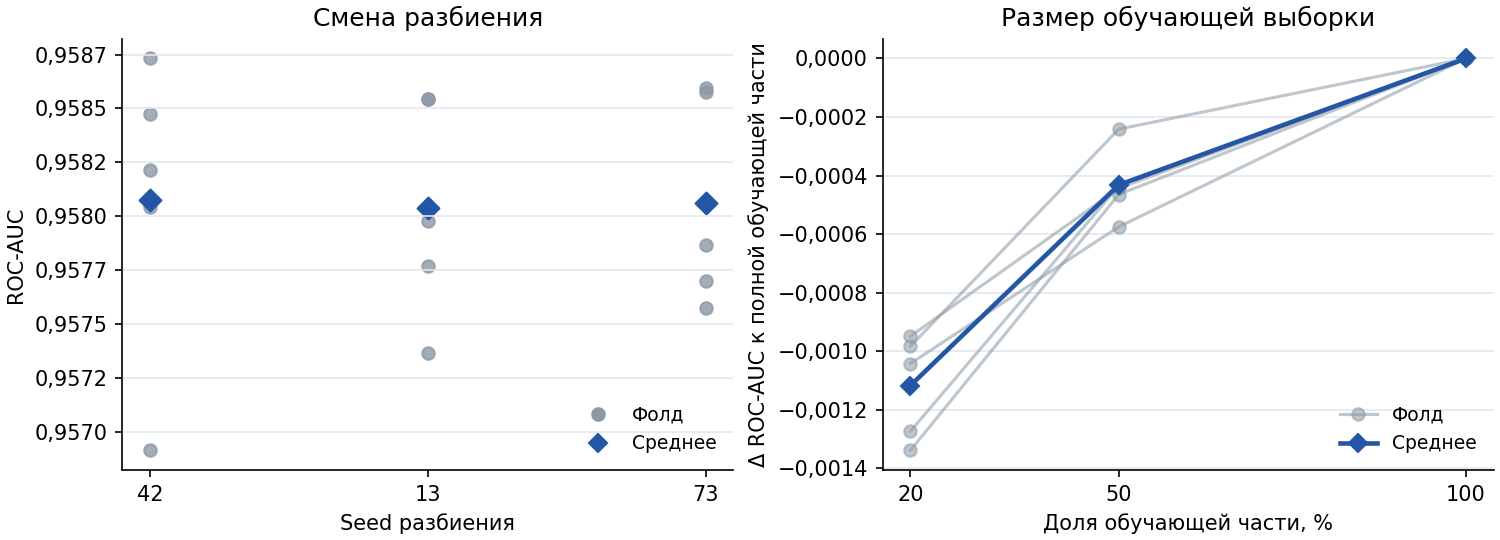

Seed разбиения,ROC-AUC,Мин. ROC-AUC,Макс. ROC-AUC
42,"0,958076","0,956913","0,958732"
13,"0,958040","0,957365","0,958546"
73,"0,958062","0,957575","0,958597"


Доля обучающих строк,Строк на фолд,ROC-AUC,Средняя разница,Мин. и макс. разница
100%,559 708,"0,958076","0,000000","+0,000000 … +0,000000"
50%,279 854,"0,957643","-0,000432","−0,000575 … −0,000241"
20%,111 941,"0,956958","-0,001118","−0,001339 … −0,000949"


In [6]:
display(Image(filename=str(report / "robustness.png"),
              alt="Средний ROC-AUC близок на трёх разбиениях. При сокращении обучающей выборки ROC-AUC снижается на каждом исходном фолде."))
folds = read("robustness_folds")
by_seed = (folds[folds.train_fraction == 1].groupby("split_seed", sort=False)
           .roc_auc.agg(["mean", "min", "max"]).reset_index())
by_seed.columns = ["Seed разбиения", "ROC-AUC", "Мин. ROC-AUC", "Макс. ROC-AUC"]
show(by_seed, {column: "{:.6f}" for column in by_seed.columns[1:]})

by_size = (folds[folds.split_seed == 42].groupby("train_fraction", sort=False)
           .agg(rows=("n_train", "min"), auc=("roc_auc", "mean"), delta=("delta_vs_full", "mean"),
                low=("delta_vs_full", "min"), high=("delta_vs_full", "max")).reset_index())
by_size["Доля обучающих строк"] = by_size.train_fraction.map(lambda f: f"{f:.0%}")
by_size["Мин. и макс. разница"] = [
    f"{low:+.6f} … {high:+.6f}".replace(".", ",").replace("-", "−")
    for low, high in zip(by_size.low, by_size.high)
]
by_size = by_size.rename(columns={"rows": "Строк на фолд", "auc": "ROC-AUC", "delta": "Средняя разница"})
show(by_size[["Доля обучающих строк", "Строк на фолд", "ROC-AUC", "Средняя разница", "Мин. и макс. разница"]],
     {"ROC-AUC": "{:.6f}", "Средняя разница": "{:.6f}"})

- **Разбиение.** Средний ROC-AUC на трёх разбиениях составил **0,958040–0,958076**. Сравниваем средние по разбиениям, поскольку состав фолдов различается.
- **Объём обучения.** На тех же проверочных строках средний ROC-AUC снизился на **0,000432** при 50% обучающей части и на **0,001118** при 20%. Метрика снизилась на всех пяти фолдах при обеих долях.

Обучающие части фолдов пересекаются. Для каждой доли мы проверили одну вложенную подвыборку на фолд. График показывает разброс в этих условиях.

## Границы применения

| Результат или ограничение | Что проверить перед применением |
|---|---|
| При пороге 0,5 модель пропускает почти две трети положительных ответов в личных поездках | Качество в нужных группах и цену обоих типов ошибок |
| Обе проверки устойчивости проведены на одном синтетическом наборе | Качество на независимых данных целевой авиакомпании |
| Оценки услуг могут появляться после рейса или вместе с итоговым ответом | Какие признаки доступны к моменту прогноза |

Для проверки разметки и разбора причин отдельных ответов нужны дополнительные данные об анкетах.

## Воспроизведение

Ноутбук читает опубликованные таблицы и графики. После повторного расчёта команда `python -m src.diagnose_hw3 --check` сравнит новые таблицы с опубликованными. [Данные, зависимости и команды запуска](../README.md#дз-3-ошибки-и-устойчивость-e3)